In [1]:
# essay_writer： 包含反思流程，多次生成直至输出结果
import os
import sqlite3

In [2]:
from langgraph.graph import StateGraph, END
from typing import TypedDict, Annotated, List
import operator
from langgraph.checkpoint.sqlite import SqliteSaver
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage

memory = SqliteSaver(sqlite3.connect(":memory:", check_same_thread=False))

In [3]:
# create agent state
class AgentState(TypedDict):
    task: str
    plan: str
    draft: str # 论文草稿
    critique: str
    content: str
    # 用于决定是否停止
    revision_number: str # 修订次数
    max_revision: str

In [4]:
from langchain_deepseek import ChatDeepSeek

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    temperature=0,
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

In [5]:
# 规划提示
PLAN_PROMPT = """You are an expert writer tasked with writing a high level outline of an essay. Write such an outline for the user provided topic. Give an outline of the essay along with any relevant notes or instructions for the sections."""

In [6]:
# 写文档的提示词
WRITER_PROMPT = """You are an essay assistant tasked with writing excellent 5-paragraph essays. \
Generate the best essay possible for the user's request and the initial outline. \
If the user provides critique, respond with a revised version of your previous attempts. \
Utilize all the information below as needed:

------

{content}"""

In [7]:
REFLECTION_PROMPT = """You are a teacher grading an essay submission.
Generate critique and recommendations for the user's submission.Provide detailed recommendations, including requests for length, depth, style, etc."""

In [8]:
RESEARCH_PLAN_PROMPT = """You are a researcher charged with providing information that can \
be used when writing the following essay. Generate a list of search queries that will gather \
any relevant information. Only generate 3 queries max."""

In [9]:
RESEARCH_CRITIQUE_PROMPT = """You are a researcher charged with providing information that can \
be used when making any requested revisions (as outlined below). \
Generate a list of search queries that will gather any relevant information. Only generate 3 queries max."""

In [10]:
from pydantic import BaseModel

In [11]:
class Queries(BaseModel):
    queries: List[str]

In [12]:
# from tavily import TavilyClient
# tavily = TavilyClient(api_key=tavily_api)
# 将tavily搜索工具改为deepseek的search服务，下载deepseek-search-cli包
from deepseek_search_cli import DeepSeekClient
# 注意max_results字段需要修改为count
deepseek_search_cli = DeepSeekClient(api_key=os.environ["DEEPSEEK_API_KEY"])

In [13]:
def plan_node(state: AgentState):
    messages = [
        SystemMessage(content=PLAN_PROMPT),
        HumanMessage(content=state['task']),
    ]
    response = model.invoke(messages)
    # 返回消息列表
    return {"plan": response.content}

# 接下来接收计划，并进行研究节点的agent

In [14]:
def research_plan_node(state: AgentState):
    # 返回Queries实例
    queries : Queries = model.with_structured_output(Queries).invoke([
        SystemMessage(content=RESEARCH_PLAN_PROMPT),
        HumanMessage(content=state['task'])
    ])
    # or 为运算符，会先算出state["content]当中的结果，因此会抛出异常，改为if写法或者get写法
    # content = state.get("content", []) # 假设取不到content，会返回默认值[]
    if "content" in state:
        content = state["content"]
    else:
        content = []
    # 检查当前state当中是否存在content字段，不存在那么就创建一个空列表作为value
    for q in queries.queries:
        response = deepseek_search_cli.search(query=q, count=2)
        # search返回的是SearchResponse对象，需要重新取值
        for r in response.results:
            # 这里负责传入摘要
            content.append(r.summary)

    return {"content": content}


In [15]:
# 创建生成节点
def generation_node(state: AgentState):

    content = "\n\n".join(state["content"] or [])
    user_message = HumanMessage(
        content=f"{state["task"]}\n\nHere is my plan:\n\n{state['plan']}"
    )
    messages = [
        SystemMessage(
            content=WRITER_PROMPT.format(content=content)
        ),
        user_message
    ]
    response = model.invoke(messages)
    return {
        "draft": response.content,
        "revision_number": state.get("revision_number", 1) + 1 # 记录修订次数
    }

In [16]:
def reflection_node(state: AgentState):
    messages = [
        SystemMessage(content=REFLECTION_PROMPT),
        HumanMessage(content=state["draft"])
    ]

    response = model.invoke(messages)
    return {
        "critique": response.content
    }

In [17]:
def research_critique_node(state: AgentState):
    queries : Queries = model.with_structured_output(Queries).invoke([
        SystemMessage(content=RESEARCH_CRITIQUE_PROMPT),
        HumanMessage(content=state['critique'])
    ])

    content = state["content"] or []
    for q in queries.queries:
        response = deepseek_search_cli.search(query=q, count=2)
        for r in response.results:
            content.append(r.summary)
    return {
        "content": content
    }

In [18]:
def should_continue(state):
    if state["revision_number"] > state["max_revision"]:
        return END
    return "reflect" # 返回批评循环，在后续会为该步骤取名为"reflect"通过识别名称跳转

In [19]:
builder = StateGraph(AgentState)

In [20]:
builder.add_node("planner", plan_node)
builder.add_node("generate", generation_node)
builder.add_node("reflect", reflection_node)
builder.add_node("research_plan", research_plan_node)
builder.add_node("research_critique", research_critique_node)




In [21]:
builder.set_entry_point("planner")

In [22]:
builder.add_conditional_edges(
    "generate",
    should_continue,
    {
        END: END,
        "reflect": "reflect"
    }
)

In [23]:
builder.add_edge("planner", "research_plan")
builder.add_edge("research_plan", "generate")
builder.add_edge("reflect", "research_critique")
builder.add_edge("research_critique", "generate")

In [24]:
graph = builder.compile(checkpointer=memory)

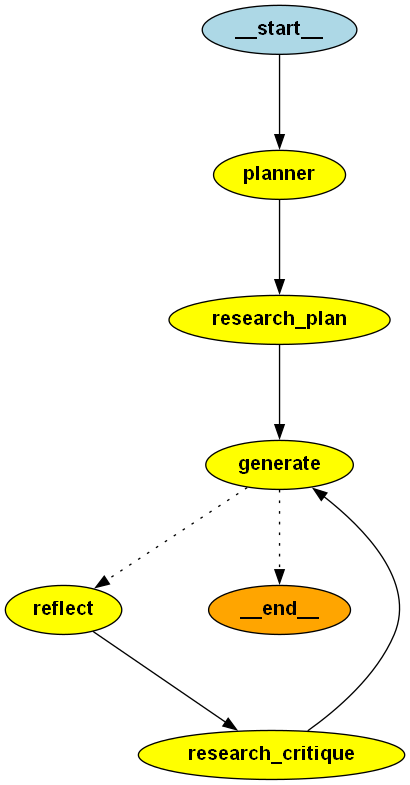

In [25]:
from IPython.display import Image

Image(graph.get_graph().draw_png())

In [26]:
# 创建写作代理
thread = {"configurable": {"thread_id": "1"}}
for s in graph.stream({
    "task": "what is the difference between langchain and langsmith",
    "max_revision": 2,
    "revision_number": 1,
}, thread):
    print(s)

# 字典当中缺少content键

{'planner': {'plan': 'Here is a high-level outline for an essay explaining the difference between LangChain and LangSmith.\n\n### Essay Outline: LangChain vs. LangSmith\n\n**Thesis Statement:** While LangChain is an open-source framework designed for *building* applications powered by large language models (LLMs), LangSmith is a commercial platform designed for *debugging, testing, and monitoring* those applications; together, they represent the "build" and "operate" phases of the LLM application lifecycle.\n\n---\n\n**I. Introduction**\n- **A. Hook:** The rapid rise of LLM applications and the complexity of managing them.\n- **B. Context:** Introduce the two products created by the same company (LangChain, Inc.) and clarify that they are not competitors but complementary tools.\n- **C. Thesis Statement:** Define the core distinction—LangChain is the construction framework, while LangSmith is the observability and evaluation platform.\n\n**II. LangChain: The Construction Framework**\n-